In [1]:
import pandas as pd
import numpy as np

df = pd.read_csv(
    "../data/processed/supply_chain_cleaned.csv",
    encoding="latin1"
)

# Cancelled orders exclude
df_model = df[
    df["Delivery Status"] != "Shipping canceled"
].copy()

# Target variable
df_model["Target"] = np.where(
    df_model["Delivery Status"] == "Late delivery",
    1,
    0
)

print("Dataset Shape:", df_model.shape)
print("\nTarget Distribution:")
print(df_model["Target"].value_counts())

Dataset Shape: (172765, 52)

Target Distribution:
Target
1    98977
0    73788
Name: count, dtype: int64


In [2]:
selected_features = [
    "Shipping Mode",
    "Days for shipment (scheduled)",
    "Customer Segment",
    "Market",
    "Order Region",
    "Department Name",
    "Category Name",
    "Order Item Quantity",
    "Order Item Discount",
    "Order Item Discount Rate",
    "Order Item Product Price"
]

X = df_model[selected_features].copy()
y = df_model["Target"].copy()

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

Features Shape: (172765, 11)
Target Shape: (172765,)


In [3]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (138212, 11)
X_test: (34553, 11)
y_train: (138212,)
y_test: (34553,)


In [4]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

In [5]:
categorical_features = X.select_dtypes(
    include=["object", "category", "string"]
).columns.tolist()

numerical_features = X.select_dtypes(
    include=["number"]
).columns.tolist()

print("Categorical Features: ", categorical_features)
print("Numerical Features: ", numerical_features)

Categorical Features:  ['Shipping Mode', 'Customer Segment', 'Market', 'Order Region', 'Department Name', 'Category Name']
Numerical Features:  ['Days for shipment (scheduled)', 'Order Item Quantity', 'Order Item Discount', 'Order Item Discount Rate', 'Order Item Product Price']


In [6]:
# Preprocessing + Model Pipeline

numerical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

logistic_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ))
])

In [7]:
# Training the model

logistic_model.fit(X_train, y_train)

print("Logistic Regression Training Completed!")

Logistic Regression Training Completed!


In [8]:
# Predictions and evaluation

y_pred = logistic_model.predict(X_test)
y_prob = logistic_model.predict_proba(X_test)[:, 1]

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1 Score:", f1_score(y_test, y_pred))
print("ROC-AUC:", roc_auc_score(y_test, y_prob))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Accuracy: 0.6979133505050212
Precision: 0.8852837025446759
Recall: 0.5430664309168982
F1 Score: 0.6731792848644248
ROC-AUC: 0.7435331421360859

Classification Report:
              precision    recall  f1-score   support

           0       0.60      0.91      0.72     14758
           1       0.89      0.54      0.67     19795

    accuracy                           0.70     34553
   macro avg       0.74      0.72      0.70     34553
weighted avg       0.76      0.70      0.69     34553


Confusion Matrix:
[[13365  1393]
 [ 9045 10750]]


In [9]:
# Random forest

from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

In [10]:
random_forest_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        max_depth=15,
        min_samples_split=10,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

In [11]:
# train the model

random_forest_model.fit(X_train, y_train)

print("Random Forest Training Completed!")

Random Forest Training Completed!


In [16]:
# generated the predictions

rf_pred = random_forest_model.predict(X_test)

rf_prob = random_forest_model.predict_proba(X_test)[:, 1]

In [17]:
# evaluate the model

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

print("Accuracy:", accuracy_score(y_test, rf_pred))
print("Precision:", precision_score(y_test, rf_pred))
print("Recall:", recall_score(y_test, rf_pred))
print("F1 Score:", f1_score(y_test, rf_pred))
print("ROC-AUC:", roc_auc_score(y_test, rf_prob))

print("\nClassification Report:")
print(classification_report(y_test, rf_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, rf_pred))

Accuracy: 0.6982606430700663
Precision: 0.8840698532426007
Recall: 0.5447335185652943
F1 Score: 0.6741060265066267
ROC-AUC: 0.7463161571304406

Classification Report:
              precision    recall  f1-score   support

           0       0.60      0.90      0.72     14758
           1       0.88      0.54      0.67     19795

    accuracy                           0.70     34553
   macro avg       0.74      0.72      0.70     34553
weighted avg       0.76      0.70      0.69     34553


Confusion Matrix:
[[13344  1414]
 [ 9012 10783]]


In [18]:
# Logistic Regression vs Random Forest

model_comparison = pd.DataFrame([
    {
        "Model": "Logistic Regression",
        "Accuracy": accuracy_score(
            y_test, logistic_model.predict(X_test)
        ),
        "Precision": precision_score(
            y_test, logistic_model.predict(X_test)
        ),
        "Recall": recall_score(
            y_test, logistic_model.predict(X_test)
        ),
        "F1 Score": f1_score(
            y_test, logistic_model.predict(X_test)
        ),
        "ROC-AUC": roc_auc_score(
            y_test, logistic_model.predict_proba(X_test)[:, 1]
        )
    },
    {
        "Model": "Random Forest",
        "Accuracy": accuracy_score(y_test, rf_pred),
        "Precision": precision_score(y_test, rf_pred),
        "Recall": recall_score(y_test, rf_pred),
        "F1 Score": f1_score(y_test, rf_pred),
        "ROC-AUC": roc_auc_score(y_test, rf_prob)
    }
])

model_comparison

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.697913,0.885284,0.543066,0.673179,0.743533
1,Random Forest,0.698261,0.884070,0.544734,0.674106,0.746316


In [25]:
from xgboost import XGBClassifier
from sklearn.pipeline import Pipeline

In [26]:
xgb_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", XGBClassifier(
        n_estimators=300,
        max_depth=6,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=42,
        eval_metric="logloss",
        n_jobs=-1
    ))
])

In [27]:
# train the model

xgb_model.fit(X_train, y_train)

print("XGBoost Training Completed!")

XGBoost Training Completed!


In [28]:
# genrate the predictions

xgb_pred = xgb_model.predict(X_test)

xgb_prob = xgb_model.predict_proba(X_test)[:, 1]

In [29]:
# model evaluation

print("Accuracy:", accuracy_score(y_test, xgb_pred))
print("Precision:", precision_score(y_test, xgb_pred))
print("Recall:", recall_score(y_test, xgb_pred))
print("F1 Score:", f1_score(y_test, xgb_pred))
print("ROC-AUC:", roc_auc_score(y_test, xgb_prob))

print("\nClassification Report:")
print(classification_report(y_test, xgb_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, xgb_pred))


Accuracy: 0.6994472260006367
Precision: 0.869309262166405
Recall: 0.559484718363223
F1 Score: 0.6808052866144152
ROC-AUC: 0.744780183696824

Classification Report:
              precision    recall  f1-score   support

           0       0.60      0.89      0.72     14758
           1       0.87      0.56      0.68     19795

    accuracy                           0.70     34553
   macro avg       0.73      0.72      0.70     34553
weighted avg       0.75      0.70      0.70     34553


Confusion Matrix:
[[13093  1665]
 [ 8720 11075]]


In [30]:
# compare all three models

models = {
    "Logistic Regression": logistic_model,
    "Random Forest": random_forest_model,
    "XGBoost": xgb_model
}

results = []

for name, model in models.items():

    predictions = model.predict(X_test)
    probabilities = model.predict_proba(X_test)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions),
        "Recall": recall_score(y_test, predictions),
        "F1 Score": f1_score(y_test, predictions),
        "ROC-AUC": roc_auc_score(y_test, probabilities)
    })

model_comparison = pd.DataFrame(results)

model_comparison.sort_values(
    by="ROC-AUC",
    ascending=False
)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
1,Random Forest,0.698261,0.884070,0.544734,0.674106,0.746316
2,XGBoost,0.699447,0.869309,0.559485,0.680805,0.744780
0,Logistic Regression,0.697913,0.885284,0.543066,0.673179,0.743533


In [31]:
from sklearn.model_selection import train_test_split

X_fit, X_val, y_fit, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

print("Model Training: ", X_fit.shape)
print("Validation: ", X_val.shape)

Model Training:  (110569, 11)
Validation:  (27643, 11)


In [32]:
# run the XGBoost

xgb_tuning_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", XGBClassifier(
        n_estimators=300,
        max_depth=6,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=42,
        eval_metric="logloss",
        n_jobs=-1
    ))
])

xgb_tuning_model.fit(X_fit, y_fit)

print("XGBoost tuning model trained!")


XGBoost tuning model trained!


In [33]:
# Validation probabilities

val_probabilities = xgb_tuning_model.predict_proba(X_val)[:, 1]

print("First 10 probabilities: ")
print(val_probabilities[:10])

First 10 probabilities: 
[0.7939051  0.9999031  0.79431105 0.38101426 0.39964792 0.36986148
 0.9998945  0.4055168  0.39185527 0.35226473]


In [34]:
# compare the  different thresholds 

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score
)

threshold_results = []

for threshold in np.arange(0.30, 0.71, 0.05):

    val_predictions = (
        val_probabilities >= threshold
    ).astype(int)

    threshold_results.append({
        "Threshold": round(threshold, 2),
        "Precision": precision_score(y_val, val_predictions),
        "Recall": recall_score(y_val, val_predictions),
        "F1 Score": f1_score(y_val, val_predictions)
    })

threshold_df = pd.DataFrame(threshold_results)

threshold_df

,Threshold,Precision,Recall,F1 Score
0,0.30,0.574622,0.996527,0.728927
1,0.35,0.580167,0.976763,0.727953
2,0.40,0.661023,0.774137,0.713122
3,0.45,0.816515,0.596262,0.689220
4,0.50,0.865405,0.554587,0.675979
5,0.55,0.880797,0.544484,0.672962
6,0.60,0.886084,0.540759,0.671634
7,0.65,0.887435,0.539622,0.671143
8,0.70,0.887860,0.538928,0.670727


In [35]:
from sklearn.base import clone

best_model = clone(xgb_tuning_model)

best_model.fit(X_train, y_train)

print("Final XGBoost Model Trained!")

Final XGBoost Model Trained!


In [38]:
selected_threshold = 0.30

test_probabilities = best_model.predict_proba(X_test)[:, 1]

test_predictions = (
    test_probabilities >= selected_threshold
).astype(int)

In [39]:
# final evaluation

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

print("Selected Threshold:", selected_threshold)

print("Accuracy:", accuracy_score(y_test, test_predictions))
print("Precision:", precision_score(y_test, test_predictions))
print("Recall:", recall_score(y_test, test_predictions))
print("F1 Score:", f1_score(y_test, test_predictions))
print("ROC-AUC:", roc_auc_score(y_test, test_probabilities))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, test_predictions))

print("\nClassification Report:")
print(classification_report(y_test, test_predictions))

Selected Threshold: 0.3
Accuracy: 0.5741614331606517
Precision: 0.573875367123208
Recall: 0.9969689315483709
F1 Score: 0.7284438210541857
ROC-AUC: 0.744780183696824

Confusion Matrix:
[[  104 14654]
 [   60 19735]]

Classification Report:
              precision    recall  f1-score   support

           0       0.63      0.01      0.01     14758
           1       0.57      1.00      0.73     19795

    accuracy                           0.57     34553
   macro avg       0.60      0.50      0.37     34553
weighted avg       0.60      0.57      0.42     34553



In [40]:
# Final Model save

import joblib
import os

os.makedirs("../models", exist_ok=True)

joblib.dump(best_model, "../models/best_model.pkl")

print("Final model saved successfully!")

Final model saved successfully!


In [41]:
from sklearn.metrics import confusion_matrix

tn, fp, fn, tp = confusion_matrix(
    y_test,
    test_predictions
).ravel()

specificity = tn / (tn + fp)

print("True Negative:", tn)
print("False Positive:", fp)
print("Specificity:", specificity)
print("False Positive Rate:", fp / (fp + tn))

True Negative: 104
False Positive: 14654
Specificity: 0.007047025342187288
False Positive Rate: 0.9929529746578127


In [42]:
from sklearn.model_selection import GroupShuffleSplit

groups = df_model.loc[X.index, "Order Id"]

# First split: 80% training, 20% testing
group_split = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, test_idx = next(
    group_split.split(X, y, groups=groups)
)

X_train_full = X.iloc[train_idx]
X_test = X.iloc[test_idx]

y_train_full = y.iloc[train_idx]
y_test = y.iloc[test_idx]

groups_train = groups.iloc[train_idx]

print("Training Shape:", X_train_full.shape)
print("Testing Shape:", X_test.shape)

Training Shape: (138493, 11)
Testing Shape: (34272, 11)


In [43]:
validation_split = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

fit_idx, val_idx = next(
    validation_split.split(
        X_train_full,
        y_train_full,
        groups=groups_train
    )
)

X_fit = X_train_full.iloc[fit_idx]
X_val = X_train_full.iloc[val_idx]

y_fit = y_train_full.iloc[fit_idx]
y_val = y_train_full.iloc[val_idx]

print("Model Training:", X_fit.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)

Model Training: (110901, 11)
Validation: (27592, 11)
Testing: (34272, 11)


In [44]:
# check target distribution

print("Training Target: ")
print(y_fit.value_counts(normalize=True))

print("\nValidation Target: ")
print(y_val.value_counts(normalize=True))

print("\nTesting Target: ")
print(y_test.value_counts(normalize=True))

Training Target: 
Target
1    0.570356
0    0.429644
Name: proportion, dtype: float64

Validation Target: 
Target
1    0.579951
0    0.420049
Name: proportion, dtype: float64

Testing Target: 
Target
1    0.575455
0    0.424545
Name: proportion, dtype: float64


In [45]:
# verify order overlap

fit_orders = set(groups_train.iloc[fit_idx])
val_orders = set(groups_train.iloc[val_idx])

test_orders = set(groups.iloc[test_idx])

print("Train-Validation Overlap:", len(fit_orders & val_orders))
print("Train-Test Overlap:", len(fit_orders & test_orders))
print("Validation-Test Overlap:", len(val_orders & test_orders))

Train-Validation Overlap: 0
Train-Test Overlap: 0
Validation-Test Overlap: 0


In [46]:
from sklearn.base import clone

group_xgb_model = Pipeline(steps=[
    ("preprocessor", clone(preprocessor)),
    ("classifier", XGBClassifier(
        n_estimators=300,
        max_depth=6,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=42,
        eval_metric="logloss",
        n_jobs=-1
    ))
])

In [47]:
group_xgb_model.fit(X_fit, y_fit)

print("Group-based XGBoost training completed!")

Group-based XGBoost training completed!


In [48]:
# validation predictions
val_probabilities = group_xgb_model.predict_proba(X_val)[:, 1]

print("Validation predictions generated!")

Validation predictions generated!


In [49]:
# Threshold comparison

threshold_results = []

for threshold in np.arange(0.30, 0.71, 0.05):

    val_predictions = (
        val_probabilities >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_val, val_predictions
    ).ravel()

    threshold_results.append({
        "Threshold": round(threshold, 2),
        "Precision": precision_score(y_val, val_predictions),
        "Recall": recall_score(y_val, val_predictions),
        "F1 Score": f1_score(y_val, val_predictions),
        "Specificity": tn / (tn + fp)
    })

group_threshold_df = pd.DataFrame(threshold_results)

group_threshold_df

,Threshold,Precision,Recall,F1 Score,Specificity
0,0.30,0.581441,0.995376,0.734077,0.010699
1,0.35,0.589371,0.967442,0.732499,0.069370
2,0.40,0.672501,0.761092,0.714060,0.488266
3,0.45,0.826820,0.594926,0.691961,0.827955
4,0.50,0.873160,0.559680,0.682128,0.887748
5,0.55,0.886357,0.549306,0.678267,0.902761
6,0.60,0.889284,0.547619,0.677831,0.905867
7,0.65,0.889702,0.546932,0.677426,0.906385
8,0.70,0.890281,0.546119,0.676970,0.907075


In [50]:
from sklearn.base import clone

final_group_model = clone(group_xgb_model)

final_group_model.fit(
    X_train_full,
    y_train_full
)

print("Final Group-based XGBoost trained!")

Final Group-based XGBoost trained!


In [51]:
# apply threshold

selected_threshold = 0.40

test_probabilities = final_group_model.predict_proba(
    X_test
)[:, 1]

test_predictions = (
    test_probabilities >= selected_threshold
).astype(int)

In [52]:
# final evaluation

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

tn, fp, fn, tp = confusion_matrix(
    y_test,
    test_predictions
).ravel()

print("Selected Threshold:", selected_threshold)

print("Accuracy:", accuracy_score(y_test, test_predictions))
print("Precision:", precision_score(y_test, test_predictions))
print("Recall:", recall_score(y_test, test_predictions))
print("F1 Score:", f1_score(y_test, test_predictions))
print("ROC-AUC:", roc_auc_score(y_test, test_probabilities))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, test_predictions))

print("\nSpecificity:", tn / (tn + fp))
print("False Positive Rate:", fp / (fp + tn))

Selected Threshold: 0.4
Accuracy: 0.6460667600373483
Precision: 0.6682027649769585
Recall: 0.7646283338403813
F1 Score: 0.7131709624024593
ROC-AUC: 0.7392446692879827

Confusion Matrix:
[[ 7062  7488]
 [ 4642 15080]]

Specificity: 0.48536082474226805
False Positive Rate: 0.514639175257732


In [53]:
# save final model

import joblib
import os

os.makedirs("../models", exist_ok=True)

joblib.dump(
    final_group_model,
    "../models/best_model.pkl"
)

print("Final model saved successfully!")

Final model saved successfully!


In [54]:
# extracted the feature importance

import pandas as pd

# Trained XGBoost classifier
xgb_classifier = final_group_model.named_steps["classifier"]

# Preprocessed feature names
feature_names = (
    final_group_model
    .named_steps["preprocessor"]
    .get_feature_names_out()
)

# Feature importance values
importance_values = xgb_classifier.feature_importances_

feature_importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance_values
})

feature_importance_df = feature_importance_df.sort_values(
    by="Importance",
    ascending=False
)

feature_importance_df.head(20)

,Feature,Importance
0,num__Days for shipment (scheduled),0.303479
5,cat__Shipping Mode_First Class,0.268391
8,cat__Shipping Mode_Standard Class,0.174202
6,cat__Shipping Mode_Same Day,0.046295
7,cat__Shipping Mode_Second Class,0.039199
19,cat__Order Region_Central Africa,0.002835
41,cat__Department Name_Book Shop,0.002532
21,cat__Order Region_Central Asia,0.002530
51,cat__Category Name_Accessories,0.002489
26,cat__Order Region_North Africa,0.002416


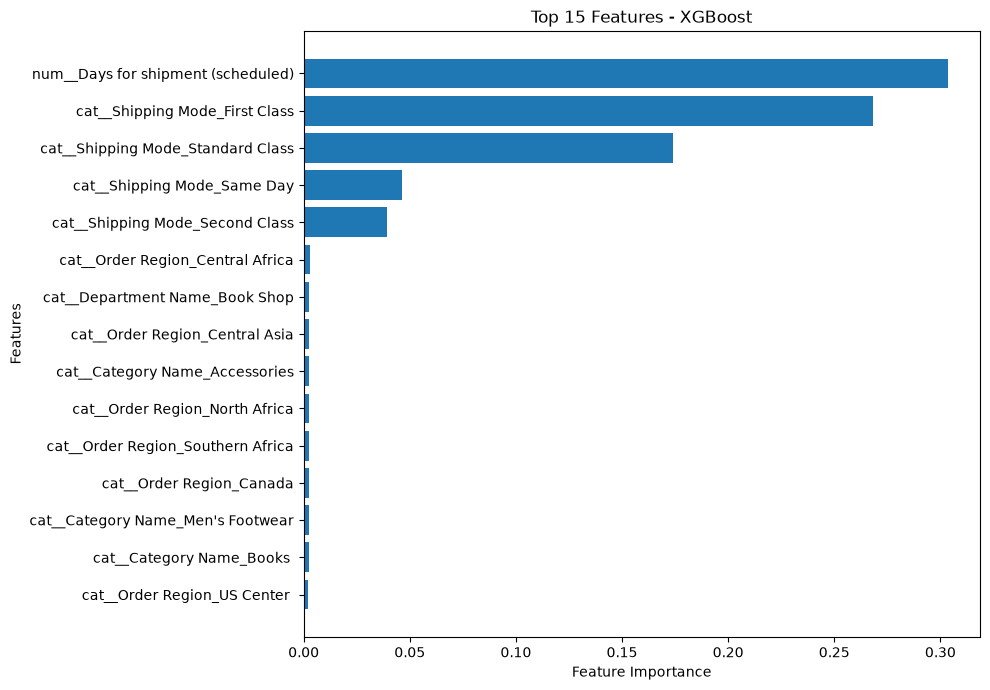

In [55]:
# Top 15 features visualize

import matplotlib.pyplot as plt

top_features = feature_importance_df.head(15).sort_values(
    by="Importance",
    ascending=True
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.xlabel("Feature Importance")
plt.ylabel("Features")
plt.title("Top 15 Features - XGBoost")

plt.tight_layout()
plt.show()


In [57]:
# save the features importance

import os

os.makedirs("../reports/figures", exist_ok=True)

feature_importance_df.to_csv(
    "../reports/figures/feature_importance.csv",
    index=False
)

plt.savefig(
    "../reports/figures/feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)

print("Feature importance saved!")

Feature importance saved!


<Figure size 640x480 with 0 Axes>